# Time Breakdown — 16K

仅保留16K上下文，比较batch 32/64/96/128下的Quest+Twilight、Quest adapter与GAS。依次运行下面两个代码单元格，即可绘图并导出PDF、PNG和CSV。

数据以显式数组放在第二个代码块顶部，维度为 `[batch, component]`，单位ms。已移除其他上下文数据、缺失点处理及多子图循环。

| 组件 | 数据含义 |
|---|---|
| Common layers | 32层公共模型计算；不是token selector |
| Independent frontend | 独立测量的选择、估分、refinement与metadata成本，累计30层 |
| Dense attention (2 layers) | 两层FlashInfer dense attention |
| Sparse attention (30 layers) | 30层对应方法的sparse attention |
| Group-Aware Sparsity | GAS 的 selection_ms 减去同 batch 下 quest_twi 的 selection_ms；用独立颜色显示 |

来源：`e7_v1_simplified_projection/E7_v1_frontend_inclusive.csv`。这是包含独立前端成本的组件估算，不是实测端到端serving时延。现有数据没有单独的token selector计时，不能用Common layers替代。

绘图略去 Output projection。GAS 的前端开销拆分为与 quest_twi 等长的 Top-p Pruning 和上述 Group-Aware Sparsity 差值，两者之和保持为原始 GAS selection_ms。此差值用于绘图分解，并非单独测量的组件计时。原始数组与 CSV 原始计时列保留；CSV 另附 top_p_pruning_ms、group_aware_sparsity_ms 和不含输出投影的 plotted_total_ms。

运行后更新同目录`time_breakdown.pdf`、`time_breakdown.png`、`time_breakdown_data.csv`。


In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pad_inches": 0.1}
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
import numpy as np
from IPython.display import display

TEAL, BLUE, ORANGE, GRAY, INK = "#008b87", "#4f7192", "#c76524", "#737b81", "#243136"

def setup_style():
    for name in ("Times New Roman.ttf", "Times New Roman Bold.ttf", "Times New Roman Italic.ttf"):
        path = Path("/System/Library/Fonts/Supplemental") / name
        if path.exists():
            font_manager.fontManager.addfont(str(path))
    plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"], "font.size": 8.5, "axes.labelsize": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.linewidth": .6, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK, "savefig.facecolor": "white", "hatch.linewidth": 0.5})

def axis_style(ax, grid_axis="both"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(width=.6, length=2, pad=2)
    ax.grid(axis=grid_axis, color="#dce2e5", linewidth=.45, zorder=0)
    ax.set_axisbelow(True)

setup_style()

Saved figures and component data to: /Users/linshengle/Documents/2026/SparseAttention/会用到的论文图与复现/fig8-TimeBreakdown


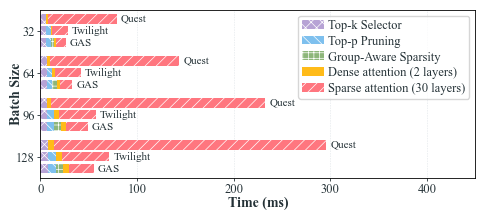

In [2]:
# Editable time-breakdown data, in milliseconds (2026-10-23).
# Array axes: [batch, component]; only 16K context.
# Batches: 32/64/96/128. Context: 16K.
# Component order: common, independent frontend, 2 dense layers,
#                  30 sparse layers, output projection.
# Data source: E7_v1_frontend_inclusive.csv (simplified projection).
# These independently measured components do not form a connected serving test.
from numpy import true_divide


BREAKDOWN_BATCHES = (32, 64, 96, 128)
BREAKDOWN_LENGTH = 16384
BREAKDOWN_METHODS = ("quest","quest_twi", "gas")
BREAKDOWN_LABELS = {"quest_twi": "Twilight", "quest": "Quest", "gas": "GAS"}
BREAKDOWN_COMPONENT_KEYS = ("common_ms", "selection_ms", "dense_attention_ms", "sparse_attention_ms", "output_ms")

BREAKDOWN_MS = {
    # "quest": np.array([
    #     [6.5350357386, 0.0000000000, 1.7534807713, 84.6104834901, 0.7928299512],  # Batch 32: 92.899
    #     [7.3255634870, 0.0000000000, 3.2161395621, 151.2202969509, 0.7829975052], # Batch 64: 161.762
    #     [7.6482021316, 0.0000000000, 5.0828846016, 245.4859132668, 0.8645447677], # Batch 96: 258.217
    #     [8.2980871506, 0.0000000000, 6.8558763504, 309.9040364990, 0.8972636163], # Batch 128: 325.058
    # ]),
    "quest": np.array([
        [6.5350357386, 0.0000000000, 1.7534807713, 71.62368, 0.7928299512],  # Batch 32: 92.899
        [7.3255634870, 0.0000000000, 3.2161395621, 133.90848, 0.7829975052], # Batch 64: 161.762
        [7.6482021316, 0.0000000000, 5.0828846016, 221.0304, 0.8645447677], # Batch 96: 258.217
        [8.2980871506, 0.0000000000, 6.8558763504, 282.36288, 0.8972636163], # Batch 128: 325.058
    ]),
    # "quest_twi": np.array([
    #     [6.5350357386, 5.4074616035, 1.7534807713, 21.5420228866, 0.7928299512],  # Batch 32: 35.238
    #     [7.3255634870, 6.0520662814, 3.2161395621, 33.5162306695, 0.7829975052], # Batch 64: 50.110
    #     [7.6482021316, 8.3474509567, 5.0828846016, 48.9474623101, 0.8645447677], # Batch 96: 70.026
    #     [8.2980871506, 9.3328692994, 6.8558763504, 61.8461671995, 0.8972636163], # Batch 128: 86.333
    # ]),
    "quest_twi": np.array([
        [6.5350357386, 5.4074616035, 1.7534807713, 15.79008, 0.7928299512],  # Batch 32: 35.238
        [7.3255634870, 6.0520662814, 3.2161395621, 26.78784, 0.7829975052], # Batch 64: 50.110
        [7.6482021316, 8.3474509567, 5.0828846016, 38.18496, 0.8645447677], # Batch 96: 70.026
        [8.2980871506, 9.3328692994, 6.8558763504, 48.9984, 0.8972636163], # Batch 128: 86.333
    ]),
    "gas": np.array([
        [6.5350357386, 9.5938834901, 1.7534807713, 10.1376000000, 0.7928299512],  # Batch 32: 28.020
        [7.3255634870, 11.6898569509, 3.2161395621, 13.1174400000, 0.7829975052], # Batch 64: 35.349
        [7.6482021316, 16.3767136328, 5.0828846016, 22.5792000000, 0.8645447677], # Batch 96: 51.687
        [8.2980871506, 17.9407164990, 6.8558763504, 25.5283200000, 0.8972636163], # Batch 128: 58.623
    ]),
}

for method in BREAKDOWN_METHODS:
    BREAKDOWN_MS[method][:, [0, 1, 2, 4]] *= 0.9
    
# BREAKDOWN_MS = {
    # "quest": np.array([
    #     [13.0700714771, 0.0000000000, 1.7534807713, 75.7551356597, 0.7928299512],  # Batch 32: 92.899
    #     [14.6511269740, 0.0000000000, 3.2161395621, 142.1157619297, 0.7829975052],  # Batch 64: 161.762
    #     [15.2964042632, 0.0000000000, 5.0828846016, 235.4894659821, 0.8645447677],  # Batch 96: 258.217
    #     [16.5961743012, 0.0000000000, 6.8558763504, 299.0041943262, 0.8972636163],  # Batch 128: 325.058
    # ]),
    # "quest_twi": np.array([
    #     [13.0700714771, 5.4497299894, 1.7534807713, 14.2647177622, 0.7928299512],  # Batch 32: 35.238
    #     [14.6511269740, 9.3017973595, 3.2161395621, 23.9409361044, 0.7829975052],  # Batch 64: 50.110
    #     [15.2964042632, 13.4155931058, 5.0828846016, 37.2311180295, 0.8645447677],  # Batch 96: 70.026
    #     [16.5961743012, 17.0118141769, 6.8558763504, 47.8691351715, 0.8972636163],  # Batch 128: 86.333
    # ]),
    # "gas": np.array([
    #     [13.0700714771, 8.5923789098, 1.7534807713, 10.13760, 0.7928299512],  # Batch 32: 28.02
    #     [14.6511269740, 15.4050410032, 3.2161395621, 14.06976, 0.7829975052],  # Batch 64: 35.349
    #     [15.2964042632, 24.7633905010, 5.0828846016, 24.14592, 0.8645447677],  # Batch 96: 51.687
    #     [16.5961743012, 30.8791343903, 6.8558763504, 26.91072, 0.8972636163],  # Batch 128: 58.623
    # ]),
# }


# Plotting components omit output projection and split GAS selection overhead.
BREAKDOWN_PLOT_KEYS = ("common_ms", "top_p_pruning_ms", "group_aware_sparsity_ms",
                       "dense_attention_ms", "sparse_attention_ms")


def plotting_components(component_ms):
    values = {}
    selection_idx = BREAKDOWN_COMPONENT_KEYS.index("selection_ms")
    reference_selection = np.asarray(component_ms["quest_twi"], dtype=float)[:, selection_idx]
    for method, raw in component_ms.items():
        raw = np.asarray(raw, dtype=float)
        selection = raw[:, selection_idx]
        group_aware = selection - reference_selection if method == "gas" else np.zeros_like(selection)
        assert (group_aware >= 0).all(), "GAS selection_ms must be >= quest_twi selection_ms"
        values[method] = np.column_stack((
            raw[:, 0], selection - group_aware, group_aware, raw[:, 2], raw[:, 3]))
    return values


# Appearance settings shared by bars and legend swatches.
BREAKDOWN_HATCH_COLOR = "white"  # 内部纹理颜色
BREAKDOWN_EDGE_WIDTH = 0       # 色块边框宽度；0 表示不显示边框

# Each row specifies component key, legend label, fill color, and hatch pattern.
#B7A3D5 7EC0EE F2C867 8DB67A
BREAKDOWN_STYLES = [
    # ("common_ms", "Top-k Selector", "#B5A0C2", "xxx"),
    ("common_ms", "Top-k Selector", "#B7A3D5", "xxx"),
    # ("top_p_pruning_ms", "Top-p Pruning", "#1AD5E3", "\\\\\\"),
    ("top_p_pruning_ms", "Top-p Pruning", "#7EC0EE", "\\\\\\"),
    # ("group_aware_sparsity_ms", "Group-Aware Sparsity", "#2AAE6F", "+++"),
    ("group_aware_sparsity_ms", "Group-Aware Sparsity", "#8DB67A", "+++"),
    ("dense_attention_ms", "Dense attention (2 layers)", "#FFBB19", ""),
    ("sparse_attention_ms", "Sparse attention (30 layers)", "#ff767f", "///"),
]
# BREAKDOWN_STYLES = [
#     ("common_ms", "Top-k Selector", "#8DB67A", "xxx"),
#     ("top_p_pruning_ms", "Top-p Pruning", "#1AD5E3", "\\" * 3),
#     ("group_aware_sparsity_ms", "Group-Aware Sparsity", "#B5A0C2", "+++"),
#     ("dense_attention_ms", "Dense attention (2 layers)", "#F2C867", ""),
#     ("sparse_attention_ms", "Sparse attention (30 layers)", "#FF4D4D", "///"),
# ]


def time_breakdown_figure(component_ms, batches=BREAKDOWN_BATCHES,
                          methods=BREAKDOWN_METHODS, styles=None):
    """Plot 16K components without output projection, splitting GAS selection."""
    styles = BREAKDOWN_STYLES if styles is None else styles
    values = {method: np.asarray(component_ms[method], dtype=float) for method in methods}
    for value in values.values():
        assert value.shape == (len(batches), len(BREAKDOWN_COMPONENT_KEYS))
        assert np.isfinite(value).all() and (value >= 0).all()
    values = {method: value for method, value in plotting_components(component_ms).items()
              if method in methods}
    max_total = max(np.sum(value, axis=1).max() for value in values.values())
    upper = np.ceil(max_total * 1.38 / 50) * 50
    # 画布大小
    fig, ax = plt.subplots(figsize=(5,3))
    fig.subplots_adjust(left=.12, right=.99, top=.75, bottom=.19)
    # 设置柱之间的间隙宽度
    offsets = (np.arange(len(methods)) - (len(methods)-1)/2) * .28
    axis_style(ax, "x")
    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.spines["left"].set_zorder(10)  # y 轴边框置于柱状色块上方
    ax.grid(axis="x", color="#D3D9DE", linewidth=.45, linestyle=":")
    for i, batch in enumerate(batches):
        for method, offset in zip(methods, offsets):
            components = values[method][i]
            left = 0.0
            for key, label, color, hatch in styles:
                value = components[BREAKDOWN_PLOT_KEYS.index(key)]
                if value == 0:
                    continue
                ax.barh(i + offset, value, height=.22, left=left, color=color,
                        hatch=hatch, edgecolor=BREAKDOWN_HATCH_COLOR,
                        linewidth=BREAKDOWN_EDGE_WIDTH, zorder=3)
                left += value
            ax.annotate(BREAKDOWN_LABELS[method], xy=(left, i + offset),
                        xytext=(3, 0), textcoords="offset points",
                        va="center", ha="left", fontsize=8, color=INK)
            # total_time = np.sum(component_ms[method][i, :4])
            # ax.annotate(
            #     f"{BREAKDOWN_LABELS[method]} ({total_time:.3f} ms)",
            #     xy=(left, i + offset),
            #     xytext=(3, 0),
            #     textcoords="offset points",
            #     va="center",
            #     ha="left",
            #     fontsize=7.5,
            #     color=INK
            # )
    ax.set(xlim=(0, upper), ylim=(len(batches)-.5, -.5),
           yticks=np.arange(len(batches)), yticklabels=batches,
           xticks=np.arange(0, upper+1, 100))
    ax.tick_params(axis="both", labelsize=9, pad=2)
    ax.set_xlabel("Time (ms)", labelpad=1.2,
                  fontdict={"size": 10, "weight": "bold", "fontfamily": "Times New Roman"})
    ax.set_ylabel("Batch Size", labelpad=-5,
                  fontdict={"size": 10, "weight": "bold", "fontfamily": "Times New Roman"})
    # ax.set_title("16K Context", fontsize=10, weight="bold", pad=7)
    ax.legend(
        [Patch(facecolor=c, edgecolor=BREAKDOWN_HATCH_COLOR, hatch=h,
               linewidth=BREAKDOWN_EDGE_WIDTH)
         for _, _, c, h in styles],
        [label for _, label, _, _ in styles],
        loc="upper right",
        ncol=1,
        labelspacing=0.3,      # 行间距，默认 0.5
        handletextpad=0.3,     # 色块与文字的水平间距，默认 0.8
        borderpad=0.3,         # 图例内容与边框的间距，默认 0.4
        handlelength=1.8,      # 色块长度，默认 2.0
        frameon=True,
        prop={"family": "Times New Roman", "size": 9},
    )
    return fig


setup_style()
if "fig_breakdown" in globals():
    plt.close(fig_breakdown)
fig_breakdown = time_breakdown_figure(BREAKDOWN_MS)

# Save next to this isolated notebook/script, independent of the paper sources.
if "__file__" in globals():
    OUTPUT_DIR = Path(__file__).resolve().parent
else:
    _here = Path.cwd().resolve()
    _candidates = (_here, _here / "TimeBreakdown", _here / "会用到的论文图与复现/TimeBreakdown")
    OUTPUT_DIR = next((q for q in _candidates if (q / "TimeBreakdown.ipynb").exists()), _here)
fig_breakdown.savefig(OUTPUT_DIR / "time_breakdown.pdf", bbox_inches="tight")
fig_breakdown.savefig(OUTPUT_DIR / "time_breakdown.png", dpi=220, bbox_inches="tight")

# Export raw measurements plus the displayed selection split and plotted total.
plot_values = plotting_components(BREAKDOWN_MS)
with (OUTPUT_DIR / "time_breakdown_data.csv").open("w", newline="", encoding="utf-8") as handle:
    fields = ["batch_size", "length", "method", *BREAKDOWN_COMPONENT_KEYS,
              "frontend_inclusive_projection_ms", "top_p_pruning_ms",
              "group_aware_sparsity_ms", "plotted_total_ms", "status"]
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    for i, batch in enumerate(BREAKDOWN_BATCHES):
        for method in BREAKDOWN_METHODS:
            v = BREAKDOWN_MS[method][i]
            row = {"batch_size": batch, "length": BREAKDOWN_LENGTH, "method": method,
                   "status": "available", "frontend_inclusive_projection_ms": float(v.sum())}
            row.update({k: float(x) for k, x in zip(BREAKDOWN_COMPONENT_KEYS, v)})
            plotted = plot_values[method][i]
            row.update({"top_p_pruning_ms": float(plotted[1]),
                        "group_aware_sparsity_ms": float(plotted[2]),
                        "plotted_total_ms": float(plotted.sum())})
            writer.writerow(row)
print(f"Saved figures and component data to: {OUTPUT_DIR}")
plt.show()
plt.close(fig_breakdown)
